In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("retail_store_sales_cleaned.csv")

print("Dataset Shape:", df.shape)
print("\nTransaction Amount Summary:")
print(df["Total Spent"].describe())

Dataset Shape: (10531, 11)

Transaction Amount Summary:
count    10531.000000
mean       129.640063
std         94.550620
min          5.000000
25%         52.000000
50%        108.500000
75%        192.000000
max        410.000000
Name: Total Spent, dtype: float64


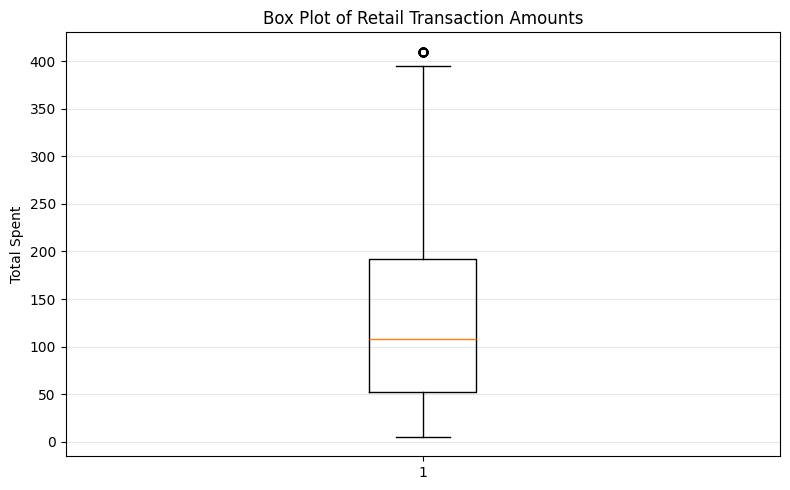

In [2]:

plt.figure(figsize=(8, 5))

plt.boxplot(df["Total Spent"])

plt.title("Box Plot of Retail Transaction Amounts")
plt.ylabel("Total Spent")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

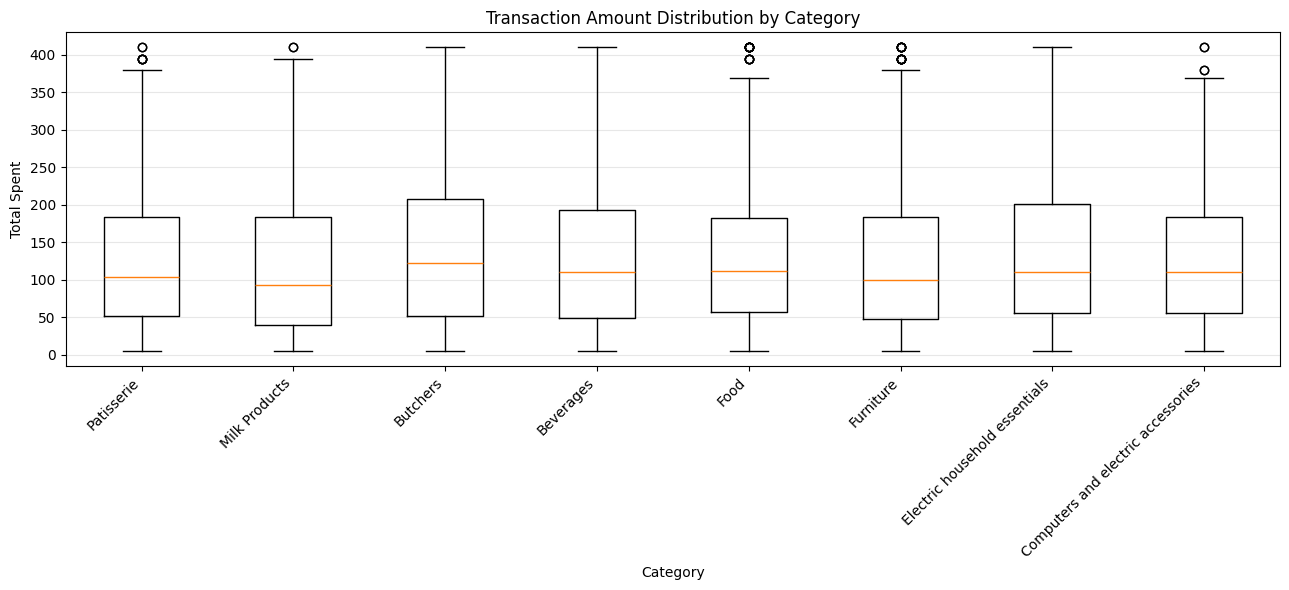

In [3]:

categories = df["Category"].unique()

data_by_category = [
    df.loc[df["Category"] == category, "Total Spent"].dropna()
    for category in categories
]

plt.figure(figsize=(13, 6))

plt.boxplot(data_by_category, tick_labels=categories)

plt.title("Transaction Amount Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Total Spent")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:

Q1 = df["Total Spent"].quantile(0.25)
Q3 = df["Total Spent"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Total Spent"] < lower_limit) |
    (df["Total Spent"] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Potential Outliers:", len(outliers))

print("\nHighest Transaction Amounts:")
print(outliers[["Category", "Total Spent"]].sort_values(
    "Total Spent", ascending=False
).head(10))

Q1: 52.0
Q3: 192.0
IQR: 140.0
Lower Limit: -158.0
Upper Limit: 402.0
Potential Outliers: 49

Highest Transaction Amounts:
                           Category  Total Spent
23                        Furniture        410.0
124                       Furniture        410.0
319                            Food        410.0
830                       Beverages        410.0
1010                      Furniture        410.0
1036                      Beverages        410.0
1401                       Butchers        410.0
1435  Electric household essentials        410.0
1497                       Butchers        410.0
1865                      Furniture        410.0


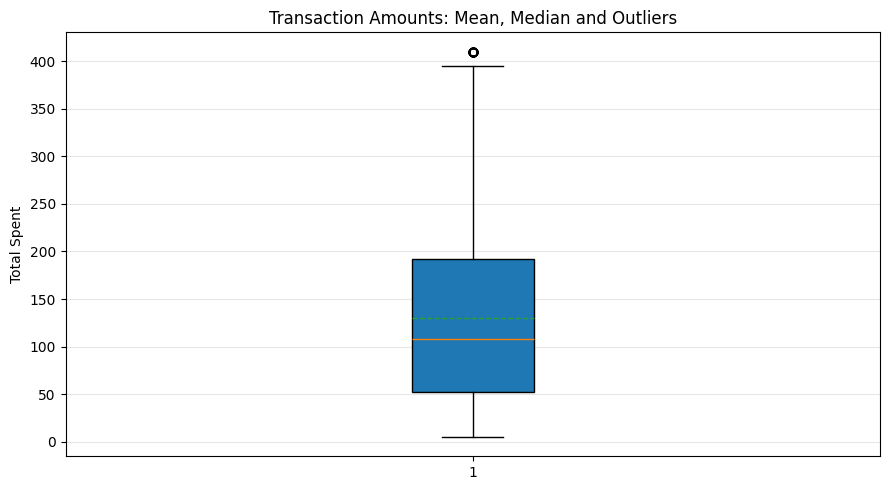

In [5]:

plt.figure(figsize=(9, 5))

plt.boxplot(
    df["Total Spent"],
    showmeans=True,
    meanline=True,
    patch_artist=True
)

plt.title("Transaction Amounts: Mean, Median and Outliers")
plt.ylabel("Total Spent")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()